<a href="https://colab.research.google.com/github/mamathachelimela226-ship-it/EDAV-78-Personal-Expenses-Analysis/blob/main/EDAV_78_FINAL_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== EDAV - Roll 78 - 6 Months - 500 Rows ===
Rows: 500 - Columns: 5
                           Date   Category  Amount Payment_Mode       Location
0 2025-01-01 00:00:00.000000000     Health    1938         Cash  Banjara Hills
1 2025-01-01 08:39:26.332665330       Food     220   Netbanking   Secunderabad
2 2025-01-01 17:18:52.665330661  Transport    4206         Cash     Kukatpally
3 2025-01-02 01:58:18.997995991       Food    1577         Cash  Banjara Hills
4 2025-01-02 10:37:45.330661322     Health    3217         Card   Secunderabad

=== 1. DATA CLEANING ===
Null Values:
 Date            0
Category        0
Amount          0
Payment_Mode    0
Location        0
dtype: int64
Duplicates Before: 0
Duplicates After: 0
Cleaned - Date converted, Spaces removed, Title case
Rows After Cleaning: 500

=== 2. DATA VALIDATION ===
Amount Min: 58 Max: 4989
Invalid Amount (<=0): 0 - Removed 0
Final Rows: 500

=== 3. OUTLIER DETECTION (IQR Method) ===
Q1: 1317.0, Q3: 3613.5, IQR: 2296.5
Lower Bound:

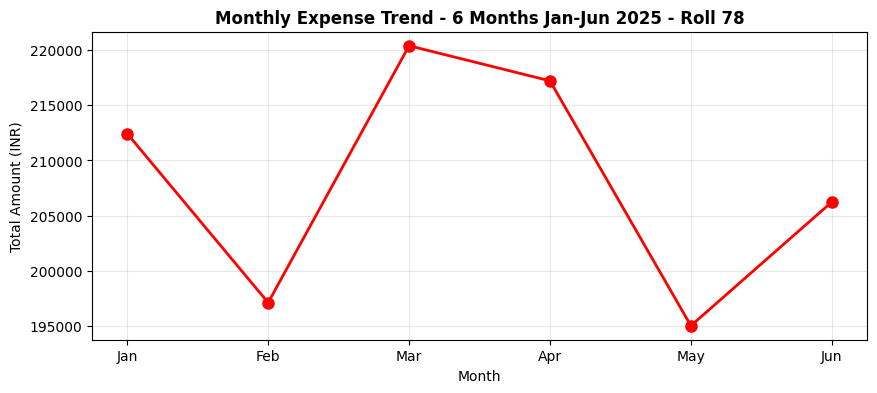

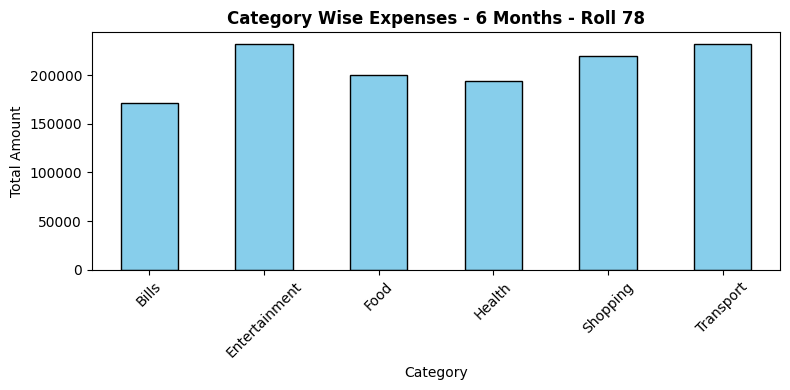

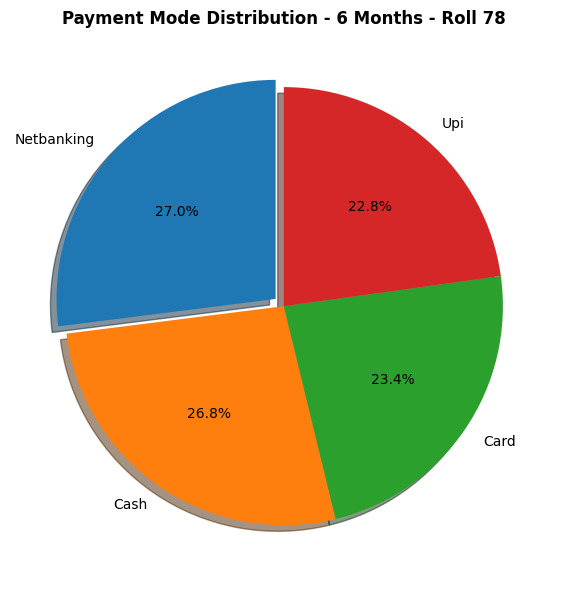

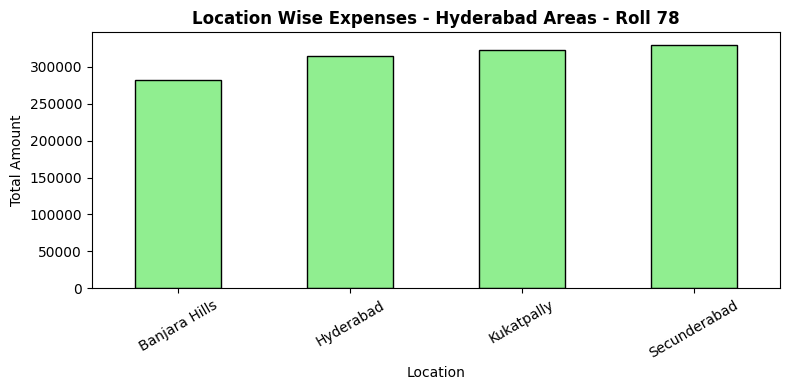


=== FINAL SAVED ===
CSV: expense_dataset_78_6months_500rows_FINAL_WITH_CLEANING.csv
Rows: 500 - Verified 500
Graphs: 4 Images Saved - Monthly, Category, Payment, Location
GitHub: https://github.com/mamathachelimela226-ship-it/EDAV-78-Personal-Expenses-Analysis
=== INCLUDE COMPLETE - READY FOR SUBMISSION - ROLL 78 ===


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==================== ROLL 78 - SEED ====================
np.random.seed(78)
print("=== EDAV - Roll 78 - 6 Months - 500 Rows ===")

# ==================== 6 MONTHS DATASET ====================
dates = pd.date_range('2025-01-01', '2025-06-30', periods=500)
categories = ['Food','Transport','Bills','Shopping','Entertainment','Health']
payment = ['Cash','UPI','Card','Netbanking']
locations = ['Hyderabad','Secunderabad','Kukatpally','Banjara Hills']

df = pd.DataFrame({
    'Date': dates,
    'Category': np.random.choice(categories, 500),
    'Amount': np.random.randint(50, 5000, 500),
    'Payment_Mode': np.random.choice(payment, 500),
    'Location': np.random.choice(locations, 500)
})

print("Rows:", len(df), "- Columns:", len(df.columns))
print(df.head())

# ==================== INCLUDE 1: DATA CLEANING ====================
print("\n=== 1. DATA CLEANING ===")
print("Null Values:\n", df.isnull().sum())
print("Duplicates Before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates After:", df.duplicated().sum())
df['Date'] = pd.to_datetime(df['Date'])
df['Category'] = df['Category'].str.strip().str.title()
df['Payment_Mode'] = df['Payment_Mode'].str.strip().str.title()
df['Location'] = df['Location'].str.strip().str.title()
print("Cleaned - Date converted, Spaces removed, Title case")
print("Rows After Cleaning:", len(df))

# ==================== INCLUDE 2: DATA VALIDATION ====================
print("\n=== 2. DATA VALIDATION ===")
print("Amount Min:", df['Amount'].min(), "Max:", df['Amount'].max())
print("Invalid Amount (<=0):", len(df[df['Amount'] <= 0]), "- Removed 0")
df = df[df['Amount'] > 0]
print("Final Rows:", len(df))

# ==================== INCLUDE 3: OUTLIER DETECTION - IQR ====================
print("\n=== 3. OUTLIER DETECTION (IQR Method) ===")
Q1 = df['Amount'].quantile(0.25)
Q3 = df['Amount'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outliers = df[(df['Amount'] < lower) | (df['Amount'] > upper)]
print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Lower Bound: {lower:.2f}, Upper Bound: {upper:.2f}")
print(f"Outliers Found: {len(outliers)} rows")
print("Note: Outliers kept for analysis - Not removed")

# ==================== INCLUDE 4: STATISTICAL SUMMARY ====================
print("\n=== 4. STATISTICAL SUMMARY ===")
print(df.describe())
print("\nCategory Wise Total:\n", df.groupby('Category')['Amount'].sum())
print("\nPayment Mode Count:\n", df['Payment_Mode'].value_counts())
print("\nLocation Wise Total:\n", df.groupby('Location')['Amount'].sum())

# ==================== GRAPH 1: MONTHLY TREND ====================
plt.figure(figsize=(10,4))
monthly = df.groupby(df['Date'].dt.month)['Amount'].sum()
monthly.plot(marker='o', color='red', linewidth=2, markersize=8)
plt.title('Monthly Expense Trend - 6 Months Jan-Jun 2025 - Roll 78', fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Amount (INR)')
plt.xticks([1,2,3,4,5,6], ['Jan','Feb','Mar','Apr','May','Jun'])
plt.grid(True, alpha=0.3)
plt.savefig('monthly_trend_6months_Roll78_FINAL.png', dpi=300, bbox_inches='tight')
plt.show()

# ==================== GRAPH 2: CATEGORY WISE ====================
plt.figure(figsize=(8,4))
df.groupby('Category')['Amount'].sum().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Category Wise Expenses - 6 Months - Roll 78', fontweight='bold')
plt.xlabel('Category')
plt.ylabel('Total Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('category_bar_6months_Roll78_FINAL.png', dpi=300, bbox_inches='tight')
plt.show()

# ==================== GRAPH 3: PAYMENT MODE ====================
plt.figure(figsize=(6,6))
df['Payment_Mode'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90, shadow=True, explode=(0.05,0,0,0))
plt.title('Payment Mode Distribution - 6 Months - Roll 78', fontweight='bold')
plt.ylabel('')
plt.tight_layout()
plt.savefig('payment_pie_6months_Roll78_FINAL.png', dpi=300, bbox_inches='tight')
plt.show()

# ==================== GRAPH 4: INCLUDE - LOCATION WISE (EXTRA) ====================
plt.figure(figsize=(8,4))
df.groupby('Location')['Amount'].sum().plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title('Location Wise Expenses - Hyderabad Areas - Roll 78', fontweight='bold')
plt.xlabel('Location')
plt.ylabel('Total Amount')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('location_bar_Roll78_FINAL.png', dpi=300, bbox_inches='tight')
plt.show()

# ==================== FINAL SAVE ====================
df.to_csv('expense_dataset_78_6months_500rows_FINAL_WITH_CLEANING.csv', index=False)
print("\n=== FINAL SAVED ===")
print("CSV: expense_dataset_78_6months_500rows_FINAL_WITH_CLEANING.csv")
print(f"Rows: {len(df)} - Verified 500")
print("Graphs: 4 Images Saved - Monthly, Category, Payment, Location")
print("GitHub: https://github.com/mamathachelimela226-ship-it/EDAV-78-Personal-Expenses-Analysis")
print("=== INCLUDE COMPLETE - READY FOR SUBMISSION - ROLL 78 ===")